# Sentinel-2 NDVI at the 2026 field plots, with NISAR

NDVI from Sentinel-2 L2A (`scripts/fetch_s2_ndvi.py`): 3x3 window at 10 m on each
gauge, SCL-masked to classes 4/5/6 (vegetation, bare, water), offset-corrected
reflectance. A gauge-day counts as clear with >= 5 of 9 valid pixels.

**Gap to know about:** 37 of 118 scenes failed to read -- 31 of them in
April-June, i.e. the flood-up and early-canopy period. Early-season NDVI is
therefore sparser than the rest.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import matplotlib.dates as mdates, matplotlib.pyplot as plt, numpy as np, pandas as pd
plt.rcParams.update({'font.size':14,'axes.titlesize':17,'axes.labelsize':15,
    'xtick.labelsize':13,'ytick.labelsize':13,'legend.fontsize':13,
    'legend.title_fontsize':14,'figure.titlesize':20})
ROOT = next(p for p in (Path.cwd(), Path.cwd().parent) if (p/"outputs"/"nisar_analysis_table.csv").exists())

# ---- config ----
NDVI_MIN_VALID   = 5        # clear pixels of 9 for an NDVI observation to count
NDVI_MAX_GAP     = 7        # max days from a NISAR pass to the nearest clear NDVI
NDVI_BINS        = [0, 0.3, 0.5, 0.7, 1.0]   # same edges as ndvi_error_diagnostic
WATER_COL        = "water_cm_fixedbias"
WATER_VALID_CM   = (-80, 60)
DRY_THRESHOLD    = -1       # same rule as the C-band diagnostic
GAUGE_COLOR = {"W3-EC":"#1f77b4","W3-CS":"#4f9fd4","W4-EC":"#17becf","W4-CS":"#6fd4de",
               "S16":"#d62728","R8":"#ff7f0e","S0":"#2ca02c"}

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
nd = pd.read_csv(ROOT/"outputs"/"ndvi_2026_at_gauges.csv"); nd["date"]=pd.to_datetime(nd.date)
nd_clear = nd[nd.n_valid >= NDVI_MIN_VALID]

d = pd.read_csv(ROOT/"outputs"/"nisar_analysis_table.csv"); d["acq_local"]=pd.to_datetime(d.acq_local)
lo, hi = WATER_VALID_CM
d[WATER_COL] = d[WATER_COL].where(d[WATER_COL].between(lo, hi))
d["ndvi_use"] = d.ndvi.where(d.ndvi_gap_days <= NDVI_MAX_GAP)
HH, HV = "hhhh_db_mean", "hvhv_db_mean"
d["ratio"] = d.ratio_db

print(f"NDVI: {len(nd_clear)} clear gauge-days of {len(nd)}")
print(f"NISAR rows with NDVI <= {NDVI_MAX_GAP} d: {d.ndvi_use.notna().sum()} of {len(d)}")
print(nd_clear.groupby('gauge_id').agg(n=('date','size'), first=('date','min'), last=('date','max'),
      ndvi_max=('ndvi_mean','max')).to_string())

NDVI: 159 clear gauge-days of 240
NISAR rows with NDVI <= 7 d: 186 of 266
           n      first       last  ndvi_max
gauge_id                                    
R8        23 2026-03-18 2026-10-09  0.885527
S0        25 2026-03-18 2026-10-19  0.862275
S16       22 2026-03-18 2026-10-19  0.873913
W3-CS     22 2026-05-02 2026-10-19  0.719550
W3-EC     21 2026-03-23 2026-10-19  0.820812
W4-CS     21 2026-03-18 2026-10-19  0.900696
W4-EC     25 2026-03-18 2026-10-19  0.904100


## 1. NDVI at each field through 2026, with the NISAR pass dates

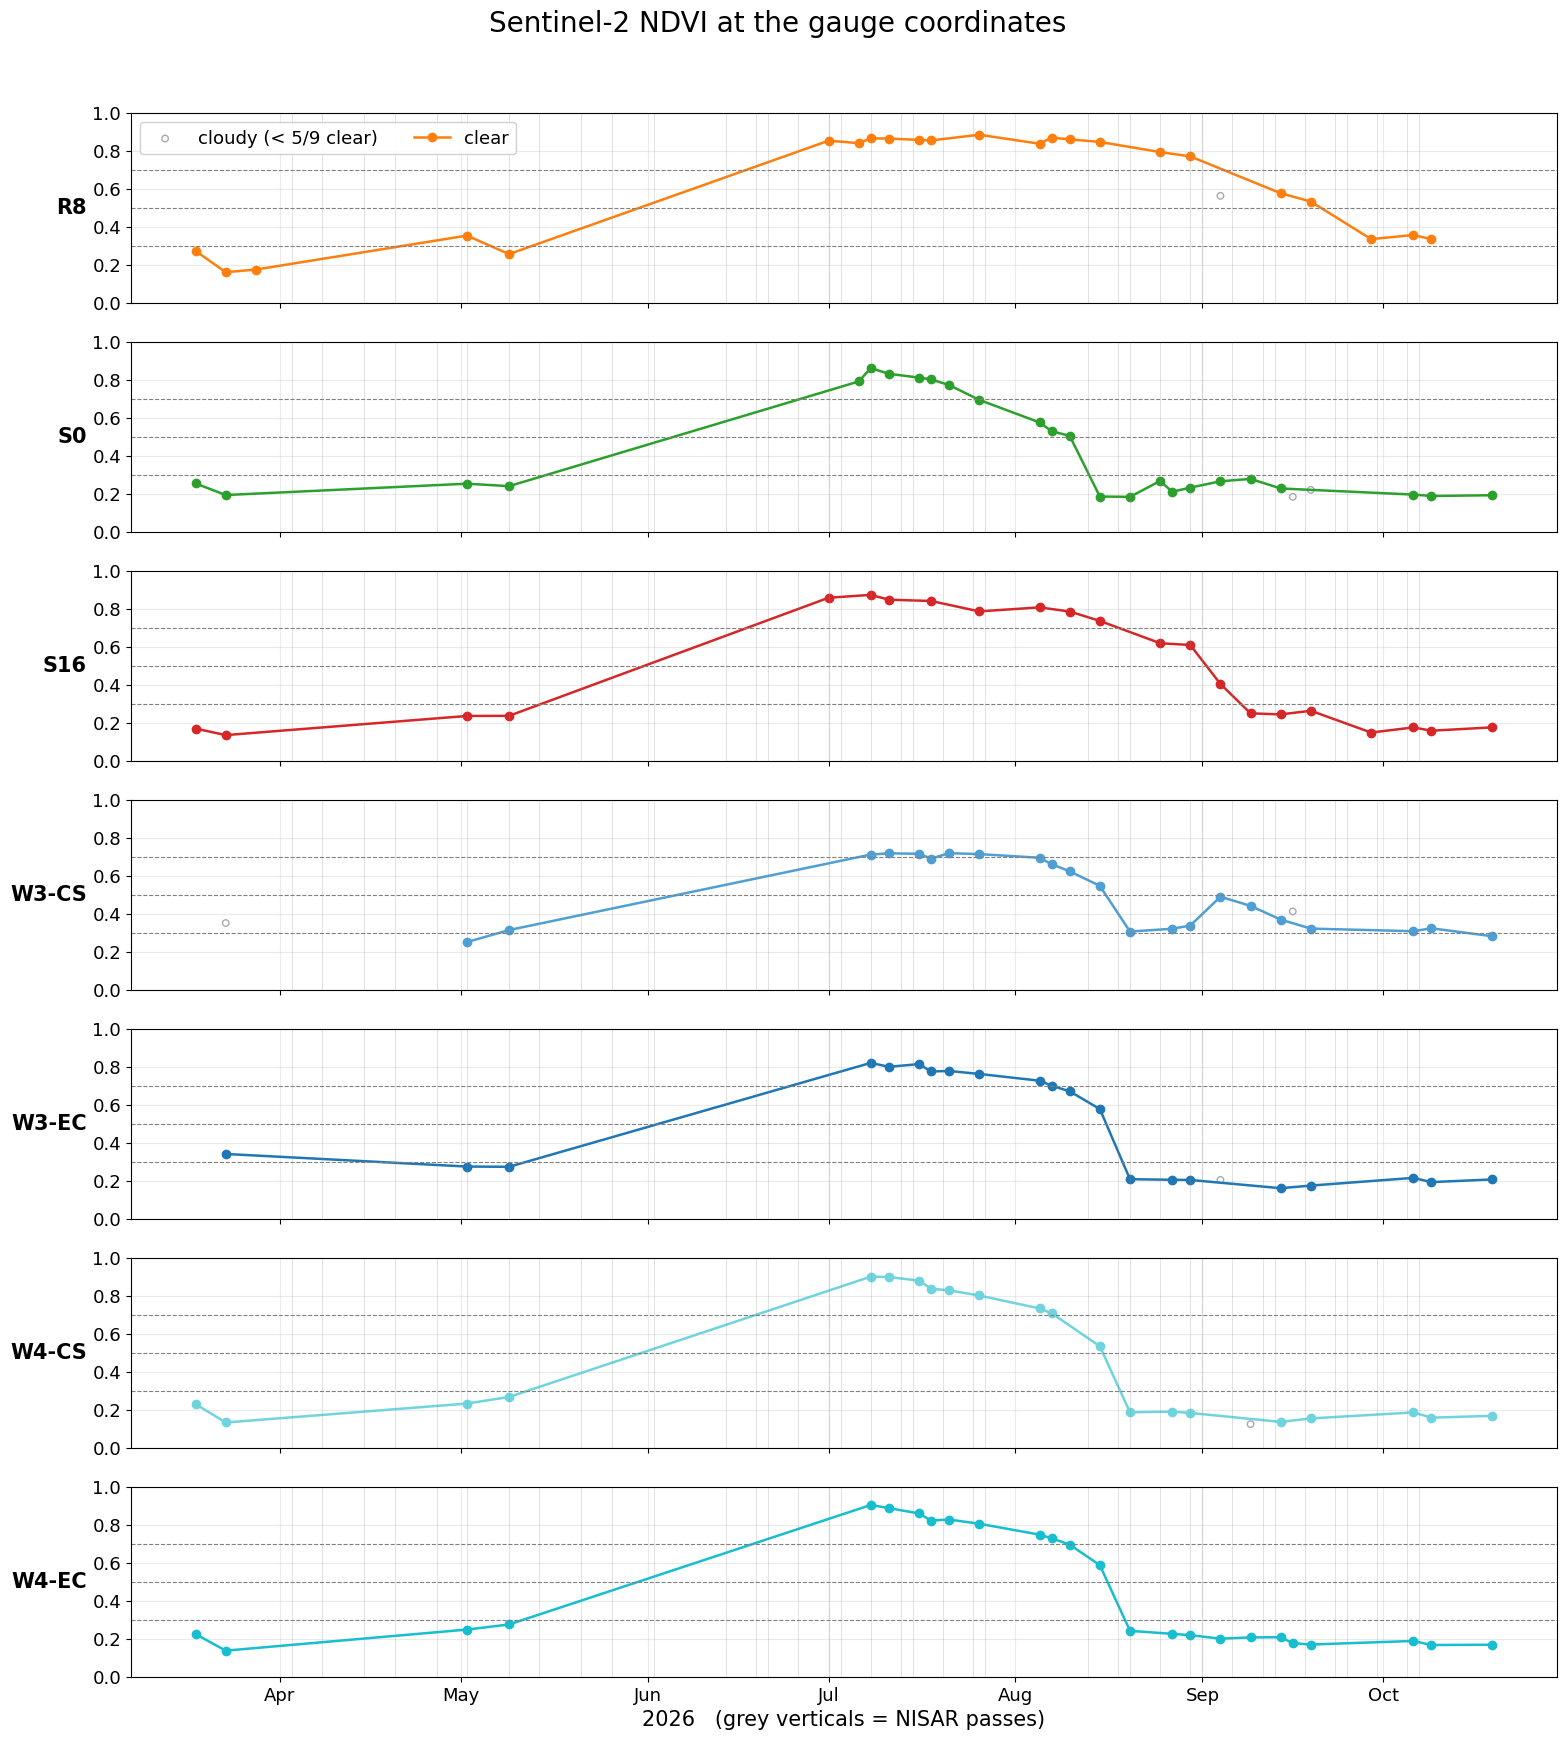

In [3]:
gauges = sorted(nd.gauge_id.unique())
fig, axes = plt.subplots(len(gauges), 1, figsize=(16, 2.5*len(gauges)), sharex=True, sharey=True)
for ax, gid in zip(axes, gauges):
    c = GAUGE_COLOR[gid]
    allg = nd[nd.gauge_id == gid]; cl = nd_clear[nd_clear.gauge_id == gid]
    ax.scatter(allg[allg.n_valid < NDVI_MIN_VALID].date, allg[allg.n_valid < NDVI_MIN_VALID].ndvi_mean,
               s=22, facecolor="none", edgecolor="#aaa", label="cloudy (< %d/9 clear)" % NDVI_MIN_VALID)
    ax.plot(cl.date, cl.ndvi_mean, "o-", color=c, ms=6, lw=1.8, label="clear")
    for t in d[d.gauge_id == gid].acq_local.dt.normalize().unique():
        ax.axvline(t, color="#888", lw=0.5, alpha=0.35)
    for b in NDVI_BINS[1:-1]:
        ax.axhline(b, color="grey", lw=0.8, ls="--")
    ax.set_ylabel(gid, rotation=0, ha="right", va="center", fontweight="bold")
    ax.set_ylim(0, 1); ax.grid(alpha=0.25)
axes[0].legend(loc="upper left", ncol=2, framealpha=0.9)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator()); axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[-1].set_xlabel("2026   (grey verticals = NISAR passes)")
fig.suptitle("Sentinel-2 NDVI at the gauge coordinates", y=0.995)
fig.tight_layout(rect=[0,0,1,0.98]); fig.savefig(ROOT/"outputs"/"ndvi_2026_timeseries.png", dpi=120, bbox_inches="tight")
plt.show()

## 2. NISAR vs NDVI, classed by the C-band rule

Same layout as the LAI version, with NDVI on the x-axis and the
0.3 / 0.5 / 0.7 bin edges from `ndvi_error_diagnostic.ipynb`. Colours are the
true class from the 2026 loggers -- there are still **no model predictions** for
2026, so this shows separability, not correctness.

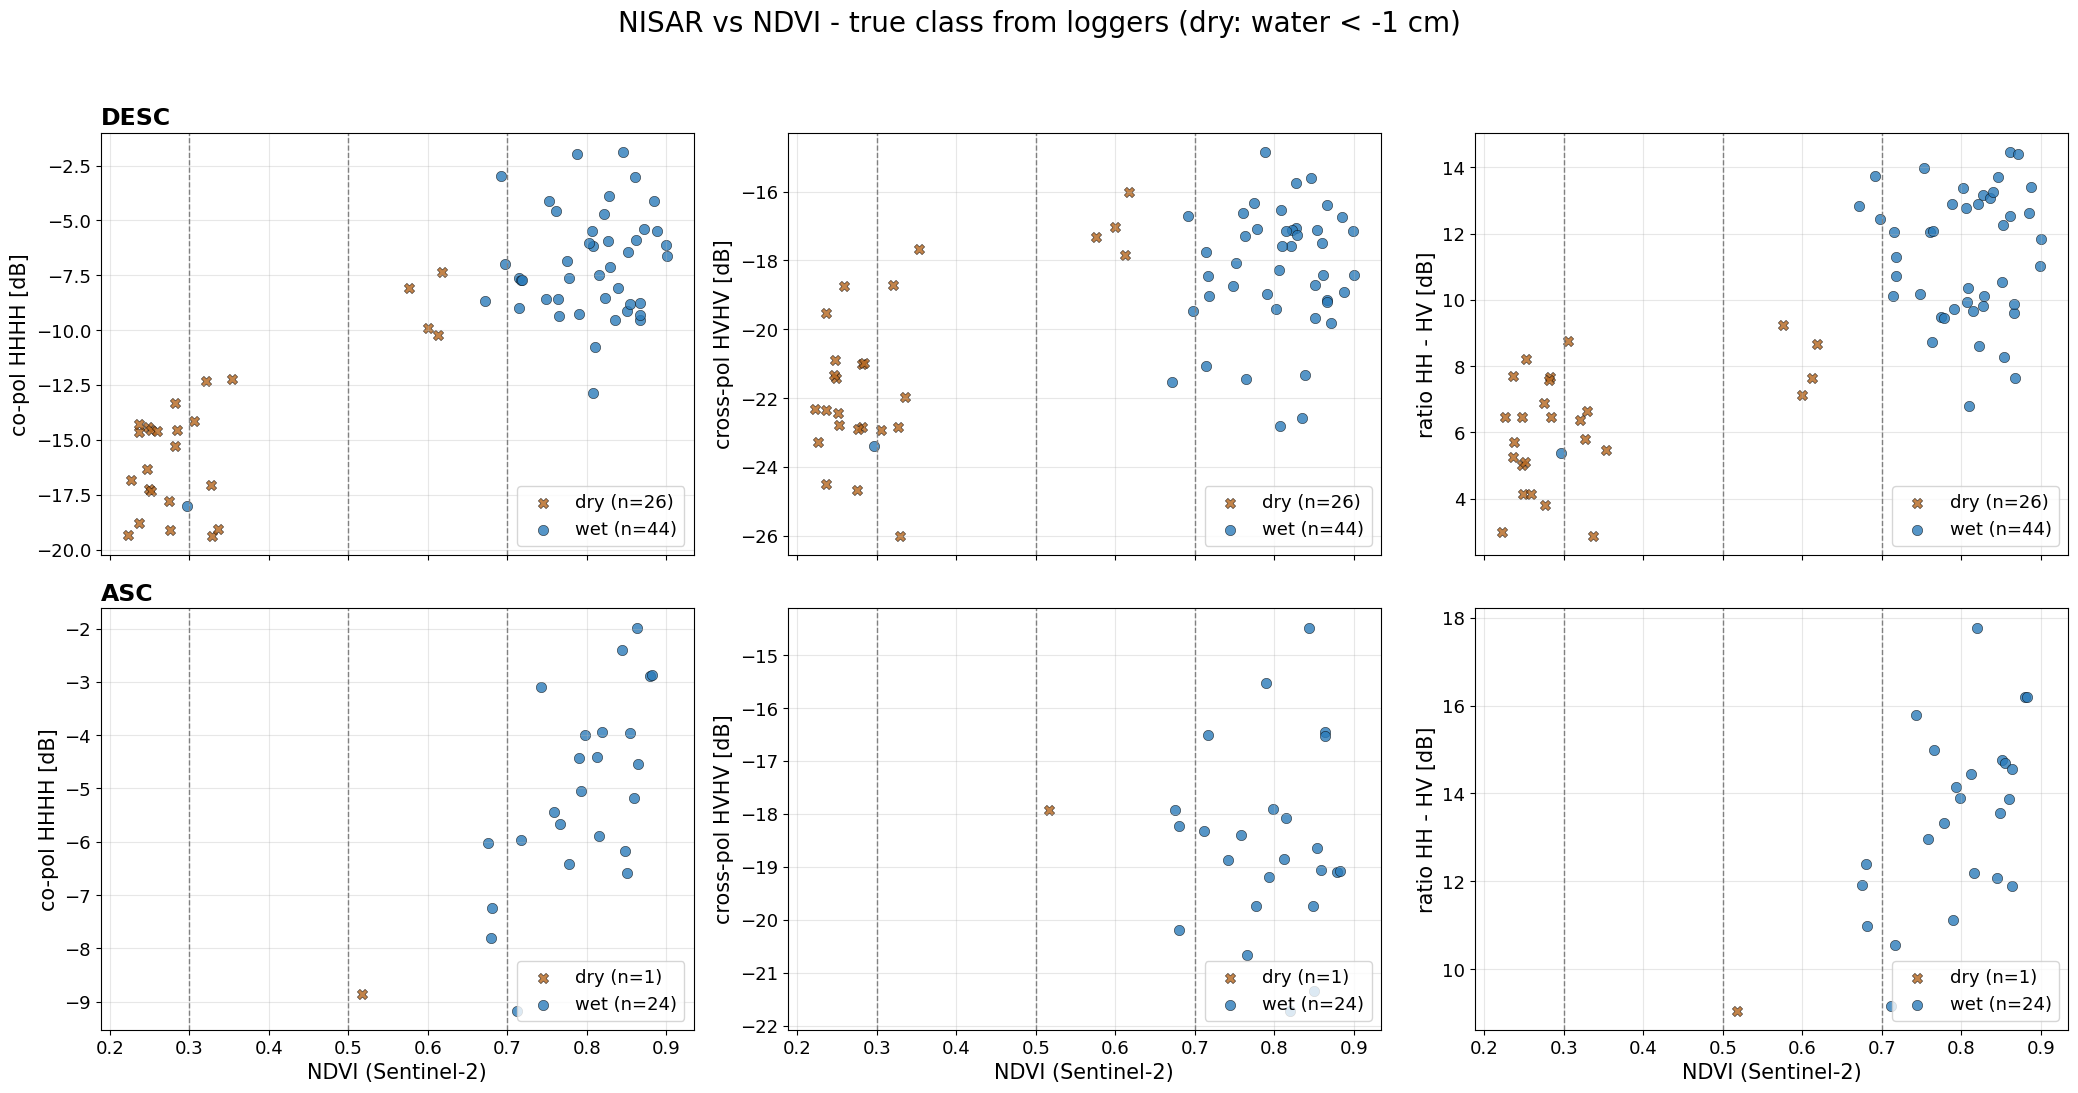

class counts per NDVI bin:
cls                   dry  wet
direction ndvi_bin            
ASC       (0.5, 0.7]    1    3
          (0.7, 1.0]    0   21
DESC      (0.0, 0.3]   16    1
          (0.3, 0.5]    6    0
          (0.5, 0.7]    4    3
          (0.7, 1.0]    0   40


In [4]:
q = d.dropna(subset=["ndvi_use", WATER_COL]).copy()
q["cls"] = np.where(q[WATER_COL] < DRY_THRESHOLD, "dry", "wet")
q["ndvi_bin"] = pd.cut(q.ndvi_use, NDVI_BINS)
COL = {"dry": "#b5651d", "wet": "#2b7bba"}

fig, axes = plt.subplots(2, 3, figsize=(21, 11), sharex=True)
for i, dr in enumerate(["DESC", "ASC"]):
    s = q[q.direction == dr]
    for j, (col, lab) in enumerate([(HH, "co-pol HHHH [dB]"), (HV, "cross-pol HVHV [dB]"), ("ratio", "ratio HH - HV [dB]")]):
        ax = axes[i][j]
        for cl, g in s.groupby("cls"):
            ax.scatter(g.ndvi_use, g[col], s=55, color=COL[cl], marker="X" if cl=="dry" else "o",
                       edgecolor="k", linewidth=0.4, alpha=0.8, label=f"{cl} (n={len(g)})")
        for b in NDVI_BINS[1:-1]: ax.axvline(b, color="grey", lw=1, ls="--")
        ax.set_ylabel(lab); ax.grid(alpha=0.3); ax.legend(loc="lower right")
        if j == 0: ax.set_title(f"{dr}", loc="left", fontweight="bold")
        if i == 1: ax.set_xlabel("NDVI (Sentinel-2)")
fig.suptitle(f"NISAR vs NDVI - true class from loggers (dry: water < {DRY_THRESHOLD} cm)", y=0.995)
fig.tight_layout(rect=[0,0,1,0.97]); fig.savefig(ROOT/"outputs"/"nisar_vs_ndvi.png", dpi=120, bbox_inches="tight")
plt.show()

print("class counts per NDVI bin:")
print(pd.crosstab([q.direction, q.ndvi_bin], q.cls).to_string())

In [5]:
rows = []
for dr, s in q.groupby("direction"):
    for col, name in [(HH,"HHHH"),(HV,"HVHV"),("ratio","HH-HV")]:
        v = s[["ndvi_use", col]].dropna()
        rows.append({"direction": dr, "y": name, "n": len(v),
                     "pearson_r_vs_NDVI": round(v.corr().iloc[0,1], 3),
                     "spearman_r_vs_NDVI": round(v.corr("spearman").iloc[0,1], 3)})
pd.DataFrame(rows)

,direction,y,n,pearson_r_vs_NDVI,spearman_r_vs_NDVI
0,ASC,HHHH,25,0.708,0.650
1,ASC,HVHV,25,-0.035,-0.096
2,ASC,HH-HV,25,0.641,0.568
3,DESC,HHHH,70,0.870,0.726
4,DESC,HVHV,70,0.666,0.540
5,DESC,HH-HV,70,0.801,0.708
